In [1]:
%matplotlib widget

In [2]:
import numpy as np
import hyperspy.api as hs
import pyxem as pxm
import matplotlib.pyplot as plt

from skimage.filters import threshold_otsu, gaussian, difference_of_gaussians
from skimage.draw import circle_perimeter
from skimage.segmentation import find_boundaries
from skimage.transform import hough_circle, hough_circle_peaks

/cluster/projects/itea_lille-nv-fys/TFY4330_nanotools_2026/miniforge3/envs/pyxem_2026/lib/python3.14/site-packages/hyperspy/misc/utils.py:72: VisibleDeprecationWarning: `_get_block_pattern` has moved to `hyperspy.misc.dask_utils`. It is for internal use only and may be removed in the future.
  warnings.warn(


## Load data

In [3]:
s = hs.load("data/2.zspy", lazy=True)
s_bs = s.get_direct_beam_position(method="center_of_mass")
s_bs.compute()
s_bs_lp = s_bs.get_linear_plane()
s_bs_corr = s_bs-s_bs_lp

  0%|          | 0/225 [00:00<?, ?it/s]

In [4]:
s_sum = s.sum(axis=(-1, -2))
s_sum.compute()

  0%|          | 0/225 [00:00<?, ?it/s]

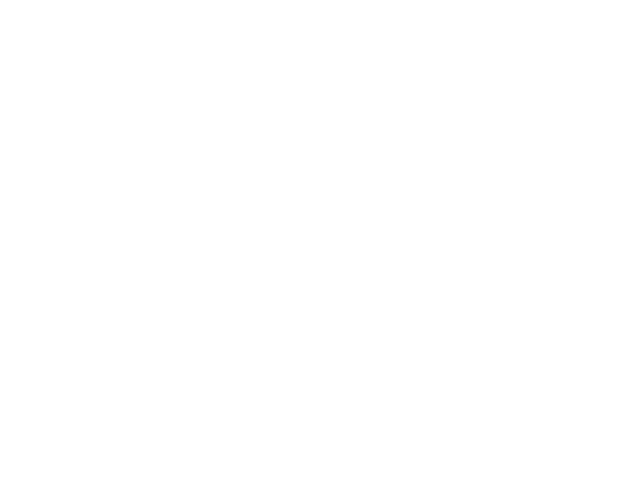

In [16]:
fig, ax = plt.subplots()
ax.set_axis_off()

In [17]:
s_sum_crop = s_sum.inav[50:214, :]

In [18]:
ax.imshow(s_sum_crop, cmap="grey")

# Gaussian

In [19]:
s_sum_gauss = gaussian(s_sum_crop.data, 1.5)

In [20]:
ax.imshow(s_sum_gauss, cmap="grey")

## Otsu

In [21]:
thresh = threshold_otsu(s_sum_gauss)
s_binary = s_sum_gauss < thresh

In [22]:
ax.imshow(s_binary, cmap="grey")

## Find Circles

In [23]:
# Inner vs outer here decides if it takes the dark or the light side of the bounadry
edges = find_boundaries(s_binary, mode="outer")
circle_radius = 8
circle_count = 47

In [24]:
hough_radii = np.array([circle_radius]*(circle_count-10)+[7]*5+[9]*5)
hough_res = hough_circle(edges, hough_radii)
accums, cx, cy, radii = hough_circle_peaks(
    hough_res,
    hough_radii,
    total_num_peaks=circle_count,
    min_xdistance=int(circle_radius*1.5),
    min_ydistance=int(circle_radius*1.5)
)

In [25]:
for center_y, center_x, radius in zip(cy, cx, radii):
    circy, circx = circle_perimeter(center_y, center_x, radius, shape=s_binary.shape)
    ax.plot(circx, circy)